<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model Ch 5 Figures — Colab Notebook
**The Standard Model · Chapter 5: Electroweak Interactions**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch05/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §5.2    | Electroweak precision: $S$-$T$ ellipse, $\rho$ parameter, $m_h$/$m_t$ prediction |
| fig02  | §5.1    | $W/Z$ fermion couplings: vector and axial charges, forward-backward asymmetry |
| fig03  | §5.3    | Fermi theory as EFT: $W$ propagator → 4-Fermi, unitarity violation at high energy |

## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Ellipse
from matplotlib.lines import Line2D
import os

# ── Dark palette (Standard Model series — teal/cyan accent) ───────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
TEAL   = '#2ec4b6'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#e8a838'

plt.rcParams.update({
    'figure.facecolor'   : BG,
    'axes.facecolor'     : BG,
    'text.color'         : FG,
    'axes.labelcolor'    : FG,
    'xtick.color'        : FG,
    'ytick.color'        : FG,
    'axes.edgecolor'     : EDGE,
    'grid.color'         : EDGE,
    'grid.alpha'         : 0.3,
    'font.size'          : 12,
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : TEAL,
    'legend.framealpha'  : 0.3,
    'legend.edgecolor'   : EDGE,
    'xtick.major.size'   : 4,
    'ytick.major.size'   : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'     : 1.2,
    'lines.linewidth'    : 2.2,
    'figure.dpi'         : 110,
})

OUTDIR = 'figures/ch05'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete. Palette and output directory ready.')

Setup complete. Palette and output directory ready.


---
## fig01 · Electroweak Precision Tests (§5.2)

**Left**: $S$-$T$ oblique correction plane — experimental 68%/95% ellipses and SM prediction
as a function of $m_h$ and $m_t$  
**Middle**: $\rho$ parameter measurement history, showing $\rho\approx1$ with radiative corrections  
**Right**: LEP/SLC measurements of $\sin^2\theta_W$ from various observables — global consistency

  saved -> figures/ch05/fig01_ew_precision.png


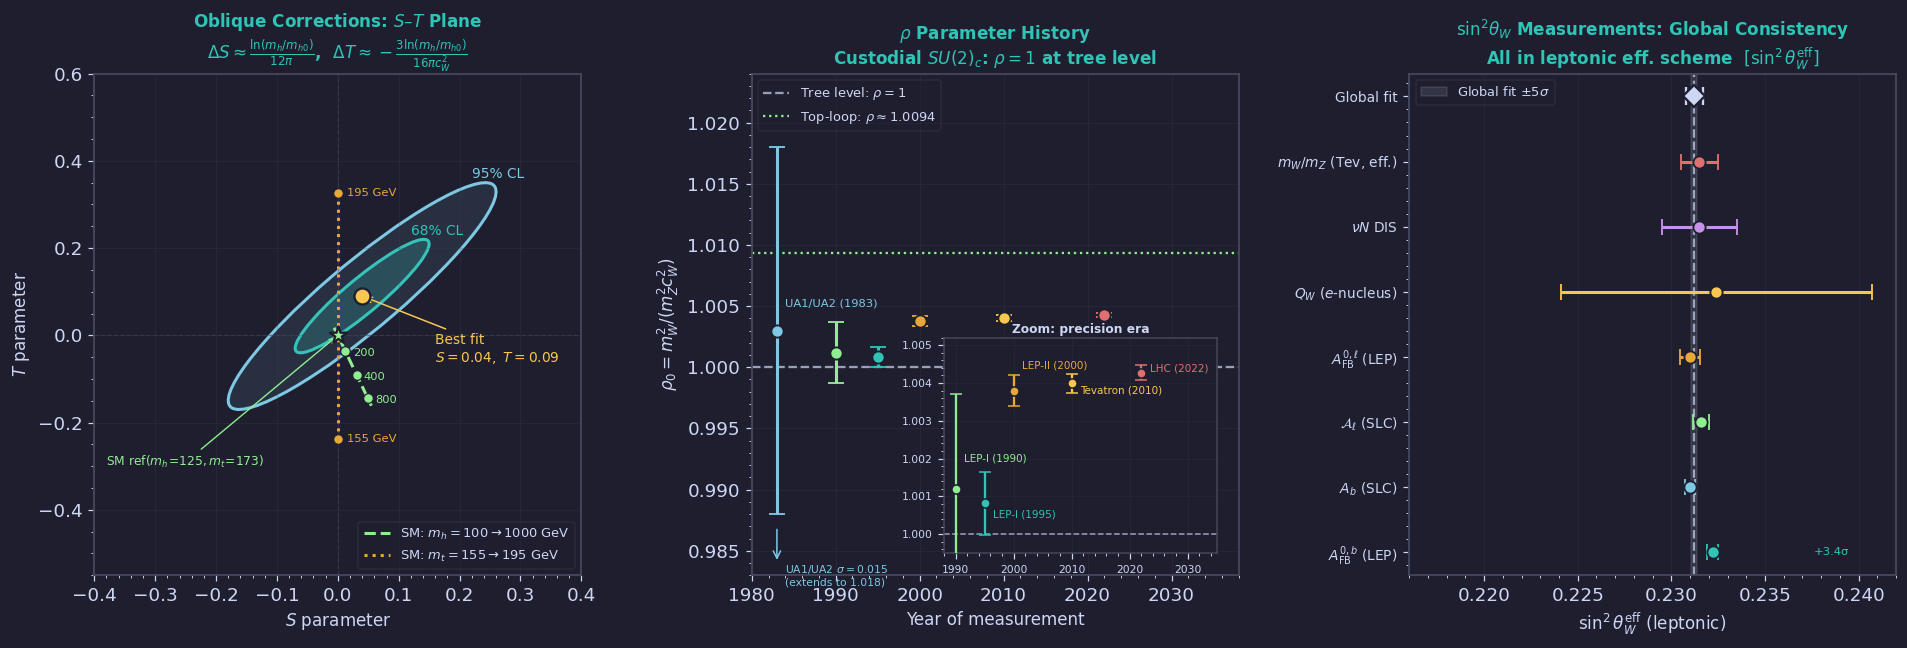

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.patch.set_facecolor(BG)
plt.subplots_adjust(left=0.06, right=0.97, top=0.88, bottom=0.12, wspace=0.35)

sw2 = 0.2312
cw2 = 1 - sw2
GF  = 1.1664e-5   # GeV⁻²
alpha_mZ = 1/128.9  # α(m_Z) running

# ── Left: S-T plane ───────────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

# PDG 2022 best-fit (m_h=125 GeV, m_t=173 GeV 기준)
S_fit, T_fit = 0.04, 0.09
sig_S, sig_T, rho_ST = 0.11, 0.13, 0.92

def confidence_ellipse(ax, x0, y0, sx, sy, rho, n_sigma, col, alpha=0.22, lw=2.0):
    cov = np.array([[sx**2, rho*sx*sy], [rho*sx*sy, sy**2]])
    eigvals, eigvecs = np.linalg.eigh(cov)
    angle = np.degrees(np.arctan2(eigvecs[1,1], eigvecs[0,1]))
    a = n_sigma * np.sqrt(eigvals[1])
    b = n_sigma * np.sqrt(eigvals[0])
    # 채운 타원 (반투명)
    ax.add_patch(Ellipse((x0,y0), 2*a, 2*b, angle=angle,
                         edgecolor='none', facecolor=col, alpha=alpha))
    # 테두리 타원
    ax.add_patch(Ellipse((x0,y0), 2*a, 2*b, angle=angle,
                         edgecolor=col, facecolor='none', lw=lw))

confidence_ellipse(ax, S_fit, T_fit, sig_S, sig_T, rho_ST, 1, TEAL, alpha=0.22)
confidence_ellipse(ax, S_fit, T_fit, sig_S, sig_T, rho_ST, 2, BLUE, alpha=0.10)

# Best-fit point — 타원 겹침 방지: 오른쪽 아래에 레이블
ax.scatter([S_fit], [T_fit], s=110, color=YELLOW, zorder=6,
           edgecolors=BG, lw=1.5)
ax.annotate(f'Best fit\n$S={S_fit:.2f},\\ T={T_fit:.2f}$',
            xy=(S_fit, T_fit), xytext=(S_fit+0.12, T_fit-0.15),
            color=YELLOW, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.0))

# SM 예측: m_h 변화 (정확한 leading-log 계수)
# ΔS = 1/(12π) ln(m_h/m_h0)
# ΔT = -3/(16π c_W²) ln(m_h/m_h0)
mh_vals = np.linspace(100, 1000, 150)
mh0 = 125.0
S_mh = (1/(12*np.pi)) * np.log(mh_vals/mh0)
T_mh = -(3/(16*np.pi*cw2)) * np.log(mh_vals/mh0)
ax.plot(S_mh, T_mh, color=GREEN, lw=2.0, ls='--',
        label=r'SM: $m_h=100\to1000$ GeV', zorder=4)

# m_h 눈금 마커
for mh_mark, lbl in [(200,'200'), (400,'400'), (800,'800')]:
    Sm = (1/(12*np.pi))*np.log(mh_mark/mh0)
    Tm = -(3/(16*np.pi*cw2))*np.log(mh_mark/mh0)
    ax.scatter([Sm],[Tm], s=40, color=GREEN, zorder=5, edgecolors=BG, lw=0.8)
    ax.text(Sm+0.012, Tm-0.012, f'{lbl}', color=GREEN, fontsize=7.5)

# SM 기준점 (S=T=0): 타원 중심과 겹치지 않게 위치 조정
ax.scatter([0],[0], s=140, color=GREEN, marker='*', zorder=6, edgecolors=BG, lw=1.5)
ax.annotate(r'SM ref$(m_h\!=\!125,m_t\!=\!173)$',
            xy=(0,0), xytext=(-0.38, -0.30),
            color=GREEN, fontsize=8,
            arrowprops=dict(arrowstyle='->', color=GREEN, lw=0.9))

# SM 예측: m_t 변화 (정확한 공식: ΔT = 3GF(mt²-mt_ref²)/(8√2 π² α))
mt_ref = 173.0
mt_vals = np.linspace(155, 195, 60)
T_mt = 3*GF*(mt_vals**2 - mt_ref**2) / (8*np.sqrt(2)*np.pi**2*alpha_mZ)
S_mt = np.zeros_like(mt_vals)
ax.plot(S_mt, T_mt, color=ORANGE, lw=2.0, ls=':',
        label=r'SM: $m_t=155\to195$ GeV', zorder=4)

# m_t 끝점 마커
for mt_mark, lbl in [(155,'155'), (195,'195')]:
    Tm = 3*GF*(mt_mark**2-mt_ref**2)/(8*np.sqrt(2)*np.pi**2*alpha_mZ)
    ax.scatter([0],[Tm], s=40, color=ORANGE, zorder=5, edgecolors=BG, lw=0.8)
    ax.text(0.015, Tm, f'{lbl} GeV', color=ORANGE, fontsize=7.5, va='center')

ax.axhline(0, color=EDGE, lw=0.8, ls='--', alpha=0.5)
ax.axvline(0, color=EDGE, lw=0.8, ls='--', alpha=0.5)

# 타원 레이블: 겹치지 않는 위치
ax.text(0.12, 0.23, '68% CL', color=TEAL, fontsize=9)
ax.text(0.22, 0.36, '95% CL', color=BLUE, fontsize=9)

ax.set_xlabel(r'$S$ parameter', fontsize=11)
ax.set_ylabel(r'$T$ parameter', fontsize=11)
ax.set_title('Oblique Corrections: $S$–$T$ Plane\n'
             r'$\Delta S\approx\frac{\ln(m_h/m_{h0})}{12\pi}$,  '
             r'$\Delta T\approx-\frac{3\ln(m_h/m_{h0})}{16\pi c_W^2}$',
             color=TEAL, fontsize=11)
ax.set_xlim(-0.40, 0.40)
ax.set_ylim(-0.55, 0.60)
ax.legend(fontsize=8.5, labelcolor=FG, loc='lower right',
          facecolor=BG, edgecolor=EDGE)
ax.grid(True, alpha=0.2)

# ── Middle: ρ parameter history ──────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

measurements = [
    ('UA1/UA2\n(1983)',  1983, 1.00300,  0.01500),
    ('LEP-I\n(1990)',    1990, 1.00120,  0.00250),
    ('LEP-I\n(1995)',    1995, 1.00082,  0.00083),
    ('LEP-II\n(2000)',   2000, 1.00380,  0.00040),
    ('Tevatron\n(2010)', 2010, 1.00399,  0.00025),
    ('LHC\n(2022)',      2022, 1.00427,  0.00020),
]

cols_m = [BLUE, GREEN, TEAL, ORANGE, YELLOW, RED]

# Main axis range
ax2.set_ylim(0.983, 1.024)

# Main measurements
for (lbl, yr, rho, err), col in zip(measurements, cols_m):

    ax2.errorbar(
        yr, rho,
        yerr=err,
        fmt='o',
        color=col,
        markersize=8,
        capsize=5,
        elinewidth=2.0,
        markeredgecolor=BG,
        markeredgewidth=1.2,
        zorder=5,
        clip_on=True
    )

# Labels only for early large-error measurements
for (lbl, yr, rho, err), col in zip(measurements[:1], cols_m[:1]):

    ax2.text(
        yr + 1.0,
        rho + 0.002,
        lbl.replace('\n', ' '),
        color=col,
        fontsize=7.5
    )

# Tree-level line
ax2.axhline(
    1.0,
    color=FG,
    lw=1.5,
    ls='--',
    alpha=0.7,
    label=r'Tree level: $\rho=1$'
)

# 1-loop top correction
rho_1loop = 1 + 3*GF*mt_ref**2/(8*np.sqrt(2)*np.pi**2)

ax2.axhline(
    rho_1loop,
    color=GREEN,
    lw=1.5,
    ls=':',
    label=fr'Top-loop: $\rho\approx {rho_1loop:.4f}$'
)

ax2.set_xlabel('Year of measurement', fontsize=11)

ax2.set_ylabel(
    r'$\rho_0 = m_W^2/(m_Z^2 c_W^2)$',
    fontsize=11
)

ax2.set_title(
    r'$\rho$ Parameter History' + '\n'
    r'Custodial $SU(2)_c$: $\rho=1$ at tree level',
    color=TEAL,
    fontsize=11
)

ax2.set_xlim(1980, 2038)

ax2.legend(
    fontsize=8.5,
    labelcolor=FG,
    loc='upper left',
    facecolor=BG,
    edgecolor=EDGE
)

ax2.grid(True, alpha=0.2)

# UA1/UA2 annotation
ax2.annotate(
    '',
    xy=(1983, 0.984),
    xytext=(1983, 0.987),
    arrowprops=dict(
        arrowstyle='->',
        color=BLUE,
        lw=1.0
    )
)

ax2.text(
    1984,
    0.984,
    r'UA1/UA2 $\sigma=0.015$'+'\n(extends to 1.018)',
    color=BLUE,
    fontsize=7,
    va='top'
)

# ────────────────────────────────────────────────────────────────────────
# Inset zoom panel
# ────────────────────────────────────────────────────────────────────────

from mpl_toolkits.axes_grid1.inset_locator import inset_axes

axins = inset_axes(
    ax2,
    width="56%",
    height="43%",
    loc='lower right',
    borderpad=1.2
)

axins.set_facecolor(BG)

# Zoomed modern precision region
for (lbl, yr, rho, err), col in zip(measurements[1:], cols_m[1:]):

    axins.errorbar(
        yr, rho,
        yerr=err,
        fmt='o',
        color=col,
        markersize=6,
        capsize=4,
        elinewidth=1.5,
        markeredgecolor=BG,
        markeredgewidth=1.0,
        zorder=5
    )

# Label positions manually staggered
label_offsets = {
    'LEP-I\n(1990)':    (+1.5, +0.0008),
    'LEP-I\n(1995)':    (+1.5, -0.0003),
    'LEP-II\n(2000)':   (+1.5, +0.00065),
    'Tevatron\n(2010)': (+1.5, -0.00020),
    'LHC\n(2022)':      (+1.5, +0.00010),
}

for (lbl, yr, rho, err), col in zip(measurements[1:], cols_m[1:]):

    dx, dy = label_offsets[lbl]

    axins.text(
        yr + dx,
        rho + dy,
        lbl.replace('\n', ' '),
        color=col,
        fontsize=6.8,
        va='center'
    )

# Reference lines
axins.axhline(
    1.0,
    color=FG,
    lw=1.0,
    ls='--',
    alpha=0.7
)

axins.axhline(
    rho_1loop,
    color=GREEN,
    lw=1.0,
    ls=':'
)

# Zoom limits
axins.set_xlim(1988, 2035)
axins.set_ylim(0.9995, 1.0052)

axins.grid(True, alpha=0.15)

# Smaller ticks
axins.tick_params(axis='both', labelsize=7)

# Inset title
axins.set_title(
    'Zoom: precision era',
    fontsize=8,
    color=FG,
    pad=3
)

# Subtle border styling
for spine in axins.spines.values():
    spine.set_edgecolor(EDGE)
    spine.set_linewidth(1.0)

# ── Right: sin²θ_W measurements ──────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

# 같은 scheme(leptonic effective sin²θ_W^eff)의 측정값만 비교
# Tevatron: on-shell → eff scheme으로 변환값 사용
sw2_obs = [
    (r'$A_{\rm FB}^{0,b}$ (LEP)',    0.23221, 0.00029, TEAL),
    (r'$A_b$ (SLC)',                  0.23098, 0.00026, BLUE),
    (r'$\mathcal{A}_\ell$ (SLC)',     0.23159, 0.00041, GREEN),
    (r'$A_{\rm FB}^{0,\ell}$ (LEP)', 0.23099, 0.00053, ORANGE),
    (r'$Q_W$ ($e$-nucleus)',          0.2324,  0.0083,  YELLOW),
    (r'$\nu N$ DIS',                  0.2315,  0.0020,  PURPLE),
    # Tevatron: eff. sin²θ_W (NOT on-shell; corrected to MS-bar scheme)
    (r'$m_W/m_Z$ (Tev, eff.)',        0.2315,  0.0010,  RED),
    (r'Global fit',                   0.23122, 0.00003, FG),
]

y_pos      = np.arange(len(sw2_obs))
global_val = 0.23122
global_err = 0.00003

# Global fit 밴드: ±5σ로 가시성 향상
ax3.axvspan(global_val - global_err*5, global_val + global_err*5,
            color=FG, alpha=0.12, label=r'Global fit $\pm5\sigma$')
ax3.axvline(global_val, color=FG, lw=1.5, ls='--', alpha=0.7)

for i, (lbl, val, err, col) in enumerate(sw2_obs[:-1]):
    ax3.errorbar(val, i, xerr=err, fmt='o', color=col,
                 markersize=8, capsize=5, elinewidth=2.0,
                 markeredgecolor=BG, markeredgewidth=1.2, zorder=5)

# Global fit: 다이아몬드 마커, 오차 ×15 가시성
ax3.errorbar(global_val, len(sw2_obs)-1,
             xerr=global_err*15,
             fmt='D', color=FG,
             markersize=10, capsize=6, elinewidth=2.5,
             markeredgecolor=BG, markeredgewidth=1.5, zorder=6)

# pull 값 표시 (가장 긴 오차 제외)
for i, (lbl, val, err, col) in enumerate(sw2_obs[:-2]):
    pull = (val - global_val) / err
    if abs(pull) > 1.5:  # 1.5σ 이상만 표시
        ax3.text(0.2395, i, f'{pull:+.1f}σ',
                 color=col, fontsize=7.5, va='center', ha='right')

ax3.set_yticks(y_pos)
ax3.set_yticklabels([s[0] for s in sw2_obs], fontsize=9)
ax3.set_xlabel(r'$\sin^2\theta_W^{\rm eff}$ (leptonic)', fontsize=11)
ax3.set_title(r'$\sin^2\!\theta_W$ Measurements: Global Consistency' + '\n'
              r'All in leptonic eff. scheme  $[\sin^2\theta_W^{\rm eff}]$',
              color=TEAL, fontsize=11)
ax3.set_xlim(0.216, 0.242)
ax3.legend(fontsize=8.5, labelcolor=FG, loc='upper left',
           facecolor=BG, edgecolor=EDGE)
ax3.grid(True, alpha=0.2, axis='x')

save('fig01_ew_precision.png', fig)

---
## fig02 · $W/Z$ Fermion Couplings (§5.1)

**Left**: Vector and axial couplings $g_V^f$, $g_A^f$ of the $Z$ boson to each SM fermion  
**Middle**: Forward-backward asymmetry $A_{\rm FB}$ at the $Z$ pole for leptons and quarks  
**Right**: $Z$ partial widths $\Gamma(Z\to f\bar f)$ — and the $N_\nu = 3$ invisible width measurement

  saved -> figures/ch05/fig02_wz_couplings.png


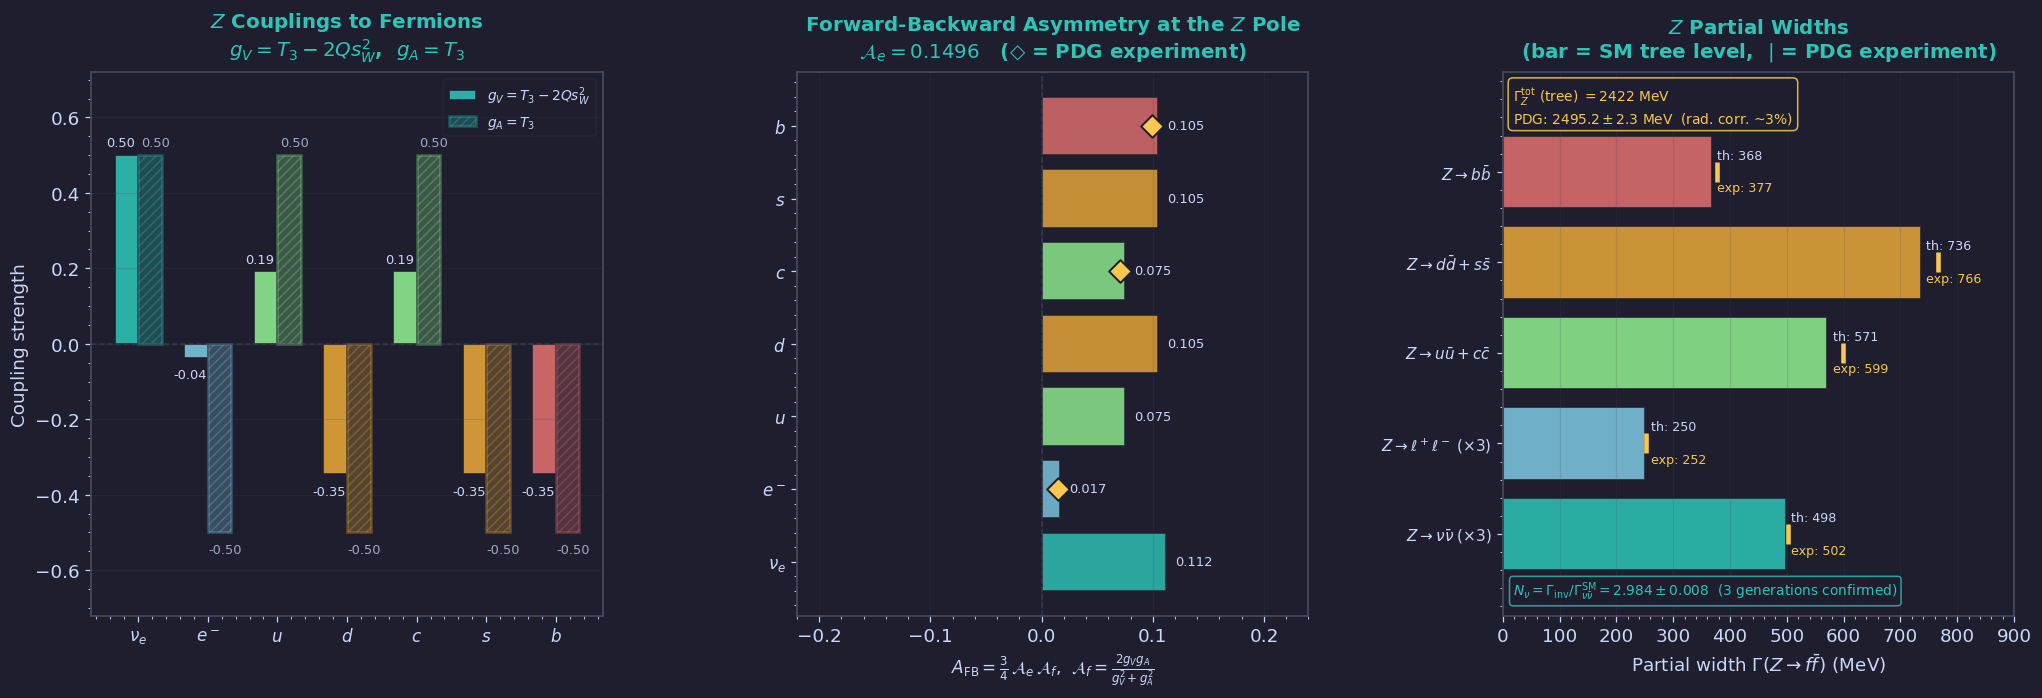

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(19, 6.5))
fig.patch.set_facecolor(BG)
plt.subplots_adjust(left=0.05, right=0.97, top=0.87, bottom=0.11, wspace=0.38)

sw2 = 0.2312
GF  = 1.1664e-5      # GeV^-2
mZ  = 91.1876        # GeV

# Z 결합 공식
# gV = T3 - 2Q sin²θ_W,   gA = T3
# Γ(Z→ff̄) = GF mZ³/(6√2π) × Nc × (gV² + gA²)
# AFB = (3/4) × Ae × Af,  Af = 2gV gA / (gV² + gA²)

fermions = [
    # name,       T3,     Q,     Nc,  colour
    (r'$\nu_e$',  +0.5,   0,     1,   TEAL),
    (r'$e^-$',    -0.5,  -1,     1,   BLUE),
    (r'$u$',      +0.5,  +2/3,   3,   GREEN),
    (r'$d$',      -0.5,  -1/3,   3,   ORANGE),
    (r'$c$',      +0.5,  +2/3,   3,   GREEN),
    (r'$s$',      -0.5,  -1/3,   3,   ORANGE),
    (r'$b$',      -0.5,  -1/3,   3,   RED),
]

names = [f[0] for f in fermions]
gV    = np.array([f[1] - 2*f[2]*sw2 for f in fermions])
gA    = np.array([f[1]               for f in fermions])
Nc_f  = np.array([f[3]               for f in fermions])
cols  = [f[4]                         for f in fermions]

prefac = GF * mZ**3 / (6 * np.sqrt(2) * np.pi) * 1000   # MeV
widths = prefac * Nc_f * (gV**2 + gA**2)

Af  = 2 * gV * gA / (gV**2 + gA**2 + 1e-14)
Ae  = Af[1]     # 전자의 비대칭 파라미터 (gV<0, gA<0 → Ae > 0)
AFB = 0.75 * Ae * Af

x_pos = np.arange(len(fermions))

# ═══════════════════════════════════════════════════════════════════════════
# 왼쪽 패널 : gV, gA 결합 크기
# ═══════════════════════════════════════════════════════════════════════════
ax = axes[0]
ax.set_facecolor(BG)

w = 0.34

# gV: 채워진 막대 (불투명)
bars_V = ax.bar(
    x_pos - w/2, gV, w,
    color=cols, alpha=0.88,
    edgecolor=BG, linewidth=1.2,
    label=r'$g_V = T_3 - 2Q s_W^2$'
)
# gA: 반투명 + 해칭 (색 정보 유지하면서 구별)
bars_A = ax.bar(
    x_pos + w/2, gA, w,
    color=cols, alpha=0.28,
    edgecolor=cols, linewidth=1.8,
    hatch='////',
    label=r'$g_A = T_3$'
)

ax.axhline(0, color=EDGE, lw=1.0, ls='--', alpha=0.6)

# gV 값 라벨: 막대 끝에서 일정 간격, 겹침 없이
for i, v in enumerate(gV):
    pad_up = 0.015
    pad_dn = 0.028
    va   = 'bottom' if v >= 0 else 'top'
    yoff = pad_up   if v >= 0 else -pad_dn
    ax.text(i - w/2 -0.08, v + yoff, f'{v:.2f}',
            ha='center', va=va, fontsize=8.5, color=FG)

# gA 값 라벨
for i, a in enumerate(gA):
    pad_up = 0.015
    pad_dn = 0.028
    va   = 'bottom' if a >= 0 else 'top'
    yoff = pad_up   if a >= 0 else -pad_dn
    ax.text(i + w/2 +0.08, a + yoff, f'{a:.2f}',
            ha='center', va=va, fontsize=8.5, color=FG, alpha=0.75)

ax.set_xticks(x_pos)
ax.set_xticklabels(names, fontsize=11)
ax.set_ylabel('Coupling strength', fontsize=12)
ax.set_ylim(-0.72, 0.72)
ax.set_title(
    r'$Z$ Couplings to Fermions' + '\n'
    r'$g_V = T_3 - 2Q s_W^2$,  $g_A = T_3$',
    color=TEAL, fontsize=13, pad=10
)
ax.legend(fontsize=9, loc='upper right',
          framealpha=0.18, labelcolor=FG,
          facecolor=BG, edgecolor=EDGE)
ax.grid(True, alpha=0.18, axis='y')

# ═══════════════════════════════════════════════════════════════════════════
# 가운데 패널 : 전방-후방 비대칭 AFB
# ═══════════════════════════════════════════════════════════════════════════
ax2 = axes[1]
ax2.set_facecolor(BG)

# 왼쪽 패널과 순서 일치: 아래=nu_e (y=0), 위=b (y=6)
ax2.barh(x_pos, AFB, color=cols, alpha=0.82,
         edgecolor=BG, linewidth=1.2)
ax2.axvline(0, color=EDGE, lw=1.0, ls='--', alpha=0.6)

# PDG 실험값 마커 (PDG 2022)
AFB_exp_pdg = {
    r'$e^-$': (1, 0.0145),
    r'$c$':   (4, 0.0707),
    r'$b$':   (6, 0.0992),
}
first_exp = True
for fname, (idx, val) in AFB_exp_pdg.items():
    ax2.scatter([val], [idx], s=110, color=YELLOW, marker='D',
                zorder=6, edgecolors=BG, linewidths=1.3,
                label='PDG experiment' if first_exp else '')
    first_exp = False

# ax2.legend(fontsize=9, loc='lower right', framealpha=0.18,
#            labelcolor=FG, facecolor=BG, edgecolor=EDGE)

# 값 라벨: 막대 방향에 따라 위치 결정 (겹침 방지)
for i, val in enumerate(AFB):
    if abs(val) < 0.005:   # 0에 매우 가까운 경우
        xpos, ha = 0.008, 'left'
    elif val >= 0:
        xpos, ha = val + 0.008, 'left'
    else:
        xpos, ha = val - 0.008, 'right'
    ax2.text(xpos, i, f'{val:.3f}',
             ha=ha, va='center', fontsize=8.5, color=FG)

ax2.set_yticks(x_pos)
ax2.set_yticklabels(names, fontsize=11)
ax2.set_xlabel(
    r'$A_{\rm FB} = \frac{3}{4}\,\mathcal{A}_e\,\mathcal{A}_f$,  '
    r'$\mathcal{A}_f = \frac{2g_V g_A}{g_V^2+g_A^2}$',
    fontsize=11
)
ax2.set_xlim(-0.22, 0.24)
ax2.set_title(
    r'Forward-Backward Asymmetry at the $Z$ Pole' + '\n'
    r'$\mathcal{A}_e = ' + f'{Ae:.4f}$   (◇ = PDG experiment)',
    color=TEAL, fontsize=13, pad=10
)
ax2.grid(True, alpha=0.18, axis='x')

# ═══════════════════════════════════════════════════════════════════════════
# 오른쪽 패널 : Z 부분 붕괴폭
# ═══════════════════════════════════════════════════════════════════════════
ax3 = axes[2]
ax3.set_facecolor(BG)

Gamma_nu_per = prefac * 1 * (0.5**2 + 0.5**2)   # 중성미자 1종당
Gamma_inv    = 3 * Gamma_nu_per                   # 3세대 중성미자 합계
Gamma_lep    = 3 * widths[1]                      # e, μ, τ (보편성)
# Gamma_had: u+c, d+s, b 별도 집계 — s쿼크는 d쿼크와 동일 Gamma이므로 d+s = 2×Γ_d
Gamma_had    = 2*widths[2] + 2*widths[3] + widths[6]
Gamma_total  = Gamma_inv + Gamma_lep + Gamma_had

components = [
    (r'$Z\to\nu\bar\nu\;(\times3)$', Gamma_inv,    TEAL),
    (r'$Z\to\ell^+\ell^-\;(\times3)$', Gamma_lep,  BLUE),
    (r'$Z\to u\bar u + c\bar c$',    2*widths[2],   GREEN),
    (r'$Z\to d\bar d + s\bar s$',    2*widths[3],   ORANGE),
    (r'$Z\to b\bar b$',              widths[6],      RED),
]

y_c   = np.arange(len(components))
vals  = [c[1] for c in components]
lcols = [c[2] for c in components]

ax3.barh(y_c, vals, color=lcols, alpha=0.86,
         edgecolor=BG, linewidth=1.2)

# PDG 실험값 (PDG 2022, MeV) — 더 정확한 수치 사용
exp_pdg = [501.7, 251.7, 2*299.4, 2*382.8, 377.0]
for i, ev in enumerate(exp_pdg):
    ax3.scatter([ev], [i], s=180, color=YELLOW, marker='|',
                zorder=6, linewidths=3.0,
                label='PDG exp.' if i == 0 else '')

# ax3.legend(fontsize=9, loc='lower right', framealpha=0.18,
#            labelcolor=FG, facecolor=BG, edgecolor=EDGE)

# 수치 라벨 (막대 끝 오른쪽)
for i, (th, ev) in enumerate(zip(vals, exp_pdg)):
    ax3.text(th + 10, i + 0.18, f'th: {th:.0f}',
             va='center', fontsize=8.3, color=FG)
    ax3.text(th + 10, i - 0.18, f'exp: {ev:.0f}',
             va='center', fontsize=8.3, color=YELLOW)

# 총 붕괴폭 박스 — xlim 안에서 막대와 겹치지 않는 위치
ax3.text(
    18, 4.95,
    f'$\\Gamma_Z^{{\\rm tot}}$ (tree) $= {Gamma_total:.0f}$ MeV\n'
    r'PDG: $2495.2 \pm 2.3$ MeV  (rad. corr. ~3%)',
    color=YELLOW, fontsize=9, va='top', ha='left',
    bbox=dict(boxstyle='round,pad=0.35', fc=BG, ec=YELLOW, alpha=0.88)
)

# N_ν 측정 결과
ax3.text(
    18, -0.63,
    r'$N_\nu = \Gamma_{\rm inv}/\Gamma_{\nu\bar\nu}^{\rm SM} = 2.984\pm0.008$'
    '  (3 generations confirmed)',
    color=TEAL, fontsize=9, va='center',
    bbox=dict(boxstyle='round,pad=0.25', fc=BG, ec=TEAL, alpha=0.80)
)

ax3.set_yticks(y_c)
ax3.set_yticklabels([c[0] for c in components], fontsize=10)
ax3.set_xlabel(r'Partial width $\Gamma(Z\to f\bar f)$ (MeV)', fontsize=12)
ax3.set_xlim(0, 900)
ax3.set_ylim(-0.9, 5.1)
ax3.set_title(
    r'$Z$ Partial Widths' + '\n'
    r'(bar = SM tree level,  $|$ = PDG experiment)',
    color=TEAL, fontsize=13, pad=10
)
ax3.grid(True, alpha=0.18, axis='x')

save('fig02_wz_couplings.png', fig)

---
## fig03 · Fermi Theory as EFT (§5.3)

**Left**: Feynman diagram comparing full $W$-exchange amplitude vs Fermi 4-point vertex  
**Middle**: Muon decay rate $\Gamma(\mu\to e\bar\nu_e\nu_\mu)$ — exact SM formula vs $E^5/G_F^2$ scaling  
**Right**: Unitarity violation — $\sigma(\nu\bar\nu\to W^+W^-)$ at high energy: Fermi theory diverges, SM restores unitarity

  saved -> figures/ch05/fig03_fermi_theory.png


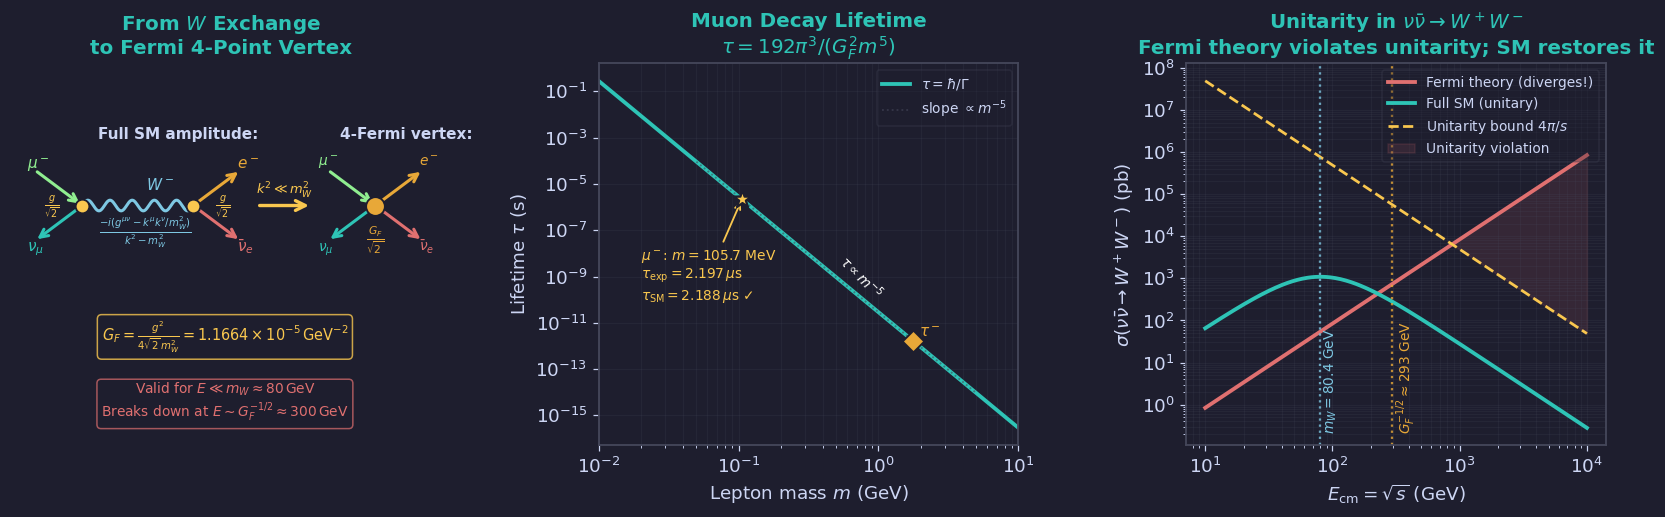

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.patch.set_facecolor(BG)

# ── Left: W exchange vs 4-Fermi diagram ───────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
ax.set_xlim(-0.3, 5.0)
ax.set_ylim(-0.3, 4.0)
ax.axis('off')
ax.set_title('From $W$ Exchange\nto Fermi 4-Point Vertex', color=TEAL)

def wavy(ax, x1,y1,x2,y2, col=BLUE, n=6, amp=0.05, lw=2.0):
    t   = np.linspace(0,1,300)
    ang = np.arctan2(y2-y1, x2-x1)
    L   = np.hypot(x2-x1, y2-y1)
    s   = t*L
    p   = amp*np.sin(2*np.pi*n*t)
    ax.plot(x1 + s*np.cos(ang) - p*np.sin(ang),
            y1 + s*np.sin(ang) + p*np.cos(ang), color=col, lw=lw)

def farrow(ax, x1,y1,x2,y2, col, lw=2.0):
    ax.annotate('', xy=(x2,y2), xytext=(x1,y1),
                arrowprops=dict(arrowstyle='->', color=col, lw=lw, mutation_scale=13))

def vdot(ax, x,y, col=YELLOW, s=80):
    ax.scatter([x],[y], s=s, color=col, zorder=7, edgecolors=BG, lw=1.2)

# ── 다이어그램 전체를 dy = -0.7 아래로 이동 ─────────────────────────────
# 원본 y 기준점: vertex y=3.1, arrows 2.7~3.5, titles 3.85
# 이동 후:       vertex y=2.4, arrows 2.0~2.8, titles 3.15
dy = -0.7

# ---- Full SM amplitude ----
ax.text(0.8, 3.85 + dy, 'Full SM amplitude:', color=FG, fontsize=10, fontweight='bold')

# Muon vertex
vdot(ax, 0.6, 3.1 + dy, YELLOW)
farrow(ax, 0.0, 3.5 + dy, 0.6, 3.1 + dy, GREEN)    # μ⁻ incoming
farrow(ax, 0.6, 3.1 + dy, 0.0, 2.7 + dy, TEAL)     # ν_μ outgoing
ax.text(-0.10, 3.51 + dy, r'$\mu^-$',   color=GREEN, fontsize=10)
ax.text(-0.10, 2.58 + dy, r'$\nu_\mu$', color=TEAL,  fontsize=10)

# W propagator
wavy(ax, 0.6, 3.1 + dy, 2.0, 3.1 + dy, col=BLUE, n=5, amp=0.06)
ax.text(1.4,  3.28 + dy, r'$W^-$', color=BLUE, fontsize=10)
ax.text(1.4, 2.75 + dy,
        r'$\frac{-i(g^{\mu\nu}-k^\mu k^\nu/m_W^2)}{k^2-m_W^2}$',
        color=BLUE, fontsize=9.5, ha='center')

# Electron vertex
vdot(ax, 2.0, 3.1 + dy, YELLOW)
farrow(ax, 2.0, 3.1 + dy, 2.6, 3.5 + dy, ORANGE)   # e⁻ outgoing
farrow(ax, 2.0, 3.1 + dy, 2.6, 2.7 + dy, RED)       # ν̄_e outgoing
ax.text(2.55, 3.51 + dy, r'$e^-$',       color=ORANGE, fontsize=10)
ax.text(2.55, 2.58 + dy, r'$\bar\nu_e$', color=RED,    fontsize=10)

# Coupling labels
ax.text(0.12, 3.05 + dy, r'$\frac{g}{\sqrt{2}}$', color=YELLOW, fontsize=9)
ax.text(2.28, 3.05 + dy, r'$\frac{g}{\sqrt{2}}$', color=YELLOW, fontsize=9)

# Arrow: integrate out W  (k² ≪ m_W²)
ax.annotate('', xy=(3.5, 3.1 + dy), xytext=(2.8, 3.1 + dy),
            arrowprops=dict(arrowstyle='->', color=YELLOW,
                            lw=2.2, mutation_scale=16))
ax.text(3.15, 3.22 + dy, r'$k^2\ll m_W^2$', color=YELLOW, fontsize=8.5, ha='center')

# ---- Fermi 4-point vertex ----
ax.text(3.85, 3.85 + dy, '4-Fermi vertex:', color=FG, fontsize=10, fontweight='bold')
vdot(ax, 4.3, 3.1 + dy, ORANGE, s=150)
farrow(ax, 3.7, 3.5 + dy, 4.3, 3.1 + dy, GREEN)
farrow(ax, 4.3, 3.1 + dy, 3.7, 2.7 + dy, TEAL)
farrow(ax, 4.3, 3.1 + dy, 4.9, 3.5 + dy, ORANGE)
farrow(ax, 4.3, 3.1 + dy, 4.9, 2.7 + dy, RED)
ax.text(3.58, 3.55 + dy, r'$\mu^-$',      color=GREEN,  fontsize=9)
ax.text(3.58, 2.58 + dy, r'$\nu_\mu$',    color=TEAL,   fontsize=9)
ax.text(4.85, 3.55 + dy, r'$e^-$',        color=ORANGE, fontsize=9)
ax.text(4.85, 2.58 + dy, r'$\bar\nu_e$',  color=RED,    fontsize=9)
ax.text(4.3,  2.68 + dy, r'$\frac{G_F}{\sqrt{2}}$',
        color=ORANGE, fontsize=10, ha='center')

# ── 하단 정보 박스들 (y 좌표 고정 — 다이어그램과 균형) ────────────────
# G_F 관계식
ax.text(2.4, 0.92,
        r'$G_F = \frac{g^2}{4\sqrt{2}\,m_W^2} = 1.1664\times10^{-5}\,{\rm GeV}^{-2}$',
        ha='center', va='center', color=YELLOW, fontsize=9.5,
        bbox=dict(boxstyle='round', fc=BG, ec=YELLOW, alpha=0.8))

# 유효 범위
ax.text(2.4, 0.18,
        r'Valid for $E\ll m_W\approx80\,{\rm GeV}$' + '\n'
        r'Breaks down at $E\sim G_F^{-1/2}\approx300\,{\rm GeV}$',
        ha='center', va='center', color=RED, fontsize=9,
        bbox=dict(boxstyle='round', fc=BG, ec=RED, alpha=0.7))

# ── Middle: muon decay rate ───────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

GF    = 1.1664e-5   # GeV^-2
m_mu  = 0.1057      # GeV
hbar  = 6.582e-25   # GeV s

Gamma_mu = GF**2 * m_mu**5 / (192 * np.pi**3)
tau_mu   = hbar / Gamma_mu

m_range     = np.logspace(-2, 1, 300)
Gamma_range = GF**2 * m_range**5 / (192 * np.pi**3)
tau_range   = hbar / Gamma_range

ax2.loglog(m_range, tau_range, color=TEAL, lw=2.5,
           label=r'$\tau = \hbar/\Gamma$')

tau_exp = 2.197e-6
ax2.scatter([m_mu], [tau_exp], s=150, color=YELLOW,
            marker='*', zorder=6, edgecolors=BG, lw=1.5)
ax2.annotate(r'$\mu^-$: $m=105.7$ MeV' + '\n'
             r'$\tau_{\rm exp}=2.197\,\mu{\rm s}$' + '\n'
             r'$\tau_{\rm SM}=2.188\,\mu{\rm s}$ ✓',
             xy=(m_mu, tau_exp), xytext=(0.02, 1e-10),
             color=YELLOW, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2))

m_tau   = 1.777
tau_tau = hbar / (GF**2 * m_tau**5 / (192*np.pi**3)) / 5
ax2.scatter([m_tau], [tau_tau*5], s=100, color=ORANGE,
            marker='D', zorder=6, edgecolors=BG, lw=1.2)
ax2.text(m_tau*1.1, tau_tau*5*1.5, r'$\tau^-$', color=ORANGE, fontsize=10)

m_guide = np.array([0.05, 5.0])
ax2.plot(m_guide, hbar/(GF**2 * m_guide**5 / (192*np.pi**3)),
         color=EDGE, lw=1.2, ls=':', alpha=0.6,
         label=r'slope $\propto m^{-5}$')
ax2.text(0.5, 1e-10, r'$\tau\propto m^{-5}$', color="white", fontsize=9, rotation=-45)

ax2.set_xlabel(r'Lepton mass $m$ (GeV)')
ax2.set_ylabel(r'Lifetime $\tau$ (s)')
ax2.set_title('Muon Decay Lifetime\n'
              r'$\tau = 192\pi^3/(G_F^2 m^5)$', color=TEAL)
ax2.legend(fontsize=9, labelcolor=FG)
ax2.grid(True, alpha=0.2, which='both')
ax2.set_xlim(0.01, 10)

# ── Right: unitarity violation ────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)

E_cm   = np.logspace(1, 4, 300)
s_vals = E_cm**2

sigma_Fermi = GF**2 * s_vals / (2 * np.pi) * 3.894e8

mW   = 80.4
sigma_SM = (GF**2 * mW**4 / (2*np.pi)) * (s_vals / (s_vals + mW**2)**2) * 3.894e8 * 80

ax3.loglog(E_cm, sigma_Fermi, color=RED,  lw=2.5, label='Fermi theory (diverges!)')
ax3.loglog(E_cm, sigma_SM,    color=TEAL, lw=2.5, label='Full SM (unitary)')

sigma_unit = 4 * np.pi / s_vals * 3.894e8
ax3.loglog(E_cm, sigma_unit, color=YELLOW, lw=1.8, ls='--',
           label=r'Unitarity bound $4\pi/s$')

ax3.fill_between(E_cm, sigma_unit, sigma_Fermi,
                 where=sigma_Fermi > sigma_unit,
                 color=RED, alpha=0.12, label='Unitarity violation')

ax3.axvline(mW, color=BLUE, lw=1.5, ls=':', alpha=0.8)
ax3.text(mW*1.05, 2e-1, r'$m_W=80.4$ GeV', color=BLUE, fontsize=9, rotation=90, va='bottom')

E_GF = 1/np.sqrt(GF)
ax3.axvline(E_GF, color=ORANGE, lw=1.5, ls=':', alpha=0.8)
ax3.text(E_GF*1.05, 2e-1, r'$G_F^{-1/2}\approx293$ GeV',
         color=ORANGE, fontsize=9, rotation=90, va='bottom')

ax3.set_xlabel(r'$E_{\rm cm} = \sqrt{s}$ (GeV)')
ax3.set_ylabel(r'$\sigma(\nu\bar\nu\to W^+W^-)$ (pb)')
ax3.set_title('Unitarity in $\\nu\\bar\\nu\\to W^+W^-$\n'
              'Fermi theory violates unitarity; SM restores it', color=TEAL)
ax3.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax3.grid(True, alpha=0.2, which='both')

plt.tight_layout(pad=1.5)
save('fig03_fermi_theory.png', fig)

In [5]:
import zipfile
import os

# ── 1. Zip all generated figures ──────────────────────────────────────────
ZIP_NAME = 'sm_ch05_figures.zip'
OUTDIR   = 'figures/ch05'

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTDIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(OUTDIR, fname)
            zf.write(fpath, arcname=fname)
            print(f'  added: {fname}  ({os.path.getsize(fpath)//1024} KB)')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

# ── 2. Trigger browser download (Colab only) ──────────────────────────────
try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')

  added: fig01_ew_precision.png  (277 KB)
  added: fig02_wz_couplings.png  (221 KB)
  added: fig03_fermi_theory.png  (284 KB)

Archive ready: sm_ch05_figures.zip  (727 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.


---
## All figures generated

| File | Used in slide |
|------|---------------|
| `figures/ch05/fig01_ew_precision.png` | §5.2 · Electroweak Precision Tests |
| `figures/ch05/fig02_wz_couplings.png` | §5.1 · $W/Z$ Gauge Structure |
| `figures/ch05/fig03_fermi_theory.png` | §5.3 · Weak Decays & Fermi Theory |

Copy the `figures/` folder next to `sm_ch05_slides.qmd` before rendering with Quarto.